# [INCEPTION 2026] — Checkpoint 5: Final Model Retraining, Competition Inference & Submission Validation
## Pelatihan Model Final, Inferensi Data Uji 359 Hari Bursa, & Audit Kepatuhan Submission

**Kompetisi:** INCEPTION 2026 Data Science Competition  
**Role:** Senior Quantitative Risk & Machine Learning Analyst — PT Investion  
**Checkpoint:** 5 (Task 3 & Tahap Final: Model Retraining, Test Inference, & Submission Verification)  
**Dataset:** Indonesia Financial Time Series Dataset 2010–2026 (`Aset Lomba/dataset peserta.csv`)  
**Target:** `Target_Volatilitas_Y` (Realized Volatility IHSG 5 hari kerja ke depan, $t+1..t+5$)  

---

### Tujuan & Ruang Lingkup Checkpoint 5

1. **Konfirmasi Konfigurasi Champion & Audit Bias Seleksi:**
   - Membandingkan secara objektif tiga kandidat utama: `Blend 50:30:20`, `Blend 60:40`, dan `GBR Tuned Standalone`.
   - Mengakui secara transparan keterbatasan *selection bias* pada validasi 2022–2024 (status *Pseudo-Holdout* 2024).
   - Menyajikan matriks keputusan terstruktur tanpa memilih model semata-mata karena grafik XAI lebih estetik atau mengklaim skor MAE yang tidak sesuai fakta numerik.

2. **Audit Pipeline Final & Verifikasi Anti-Leakage:**
   - Memastikan 29 prediktor historis diekstraksi secara strictly backward-looking ($t-W+1..t$) tanpa melibatkan harga masa depan.
   - Memverifikasi kepatuhan pra-pemrosesan: koreksi anomali skala USD/IDR diterapkan konsisten, dan `StandardScaler` hanya di-fit pada data training berlabel.
   - Menjaga integritas data uji kompetisi (tepat 359 baris, `Date >= 2025-01-02` hingga `2026-05-22`).

3. **Pelatihan Ulang Model Final (Full Historical Retraining):**
   - Melatih ulang arsitektur `GBR Tuned` (`loss='absolute_error'`, `lr=0.03`, `max_depth=2`, `n_est=100`) dan `Ridge Tuned` (`alpha=1000.0`) pada seluruh observasi berlabel yang diizinkan (2010–2024, $N=3.887$ hari bursa setelah warm-up dropna).
   - Mengevaluasi perbandingan dengan partisi *purged* ($N=3.882$) untuk mendokumentasikan dampak 5 baris batas akhir 2024.

4. **Inferensi Data Uji Kompetisi (359 Hari):**
   - Menghasilkan prediksi out-of-sample forward volatility untuk 359 hari bursa test.
   - Memverifikasi bahwa tidak ada nilai NaN, inf, atau negatif ($\min(\hat{Y}) > 0$).
   - Memeriksa konsistensi statistik distribusi terhadap realitas pasar keuangan historis.

5. **Ekspor File Submission Multi-Format & Status Validasi Template:**
   - Menghasilkan format standar 2 kolom (`Date`, `Target_Volatilitas_Y`) serta format dataset penuh terisi untuk seluruh kandidat di `outputs/submission/`.
   - Mendokumentasikan secara eksplisit bahwa komite kompetisi tidak menyertakan file `sample_submission.csv` resmi di folder aset, sehingga validasi terhadap petunjuk portal pengumpulan tetap wajib dilakukan sebelum pengunggahan final.

## 1. Setup Lingkungan, Dependensi, & Pemuatan Data

Memuat pustaka inti data science dan modul `scripts/feature_engineering.py` yang telah teruji pada checkpoint sebelumnya.

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from scipy.stats import pearsonr

# Tambahkan direktori root ke path agar modul scripts dapat diimpor
CURRENT_DIR = os.path.abspath('')
PROJECT_ROOT = os.path.dirname(CURRENT_DIR) if os.path.basename(CURRENT_DIR) == 'notebook' else CURRENT_DIR
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from scripts.feature_engineering import preprocess_usdidr, engineer_features, run_anti_leakage_and_quality_tests

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

C_BLUE = '#1f77b4'
C_ORANGE = '#ff7f0e'
C_GREEN = '#2ca02c'
C_RED = '#d62728'
C_PURPLE = '#9467bd'
C_GRAY = '#7f7f7f'

# Pemuatan data mentah
DATA_PATH = os.path.join(PROJECT_ROOT, "Aset Lomba", "dataset peserta.csv")
assert os.path.exists(DATA_PATH), f"File dataset tidak ditemukan: {DATA_PATH}"

df_raw = pd.read_csv(DATA_PATH)
df_raw['Date'] = pd.to_datetime(df_raw['Date'])
df_raw = df_raw.sort_values('Date').reset_index(drop=True)

print("=" * 70)
print("PEMUATAN DATASET SELESAI")
print("=" * 70)
print(f"Total baris dataset mentah : {len(df_raw):,} observasi")
print(f"Rentang tanggal penuh     : {df_raw['Date'].min().strftime('%Y-%m-%d')} s/d {df_raw['Date'].max().strftime('%Y-%m-%d')}")
print(f"Baris berlabel (Train/Val): {df_raw['Target_Volatilitas_Y'].notna().sum():,} baris")
print(f"Baris data uji (Test 2025): {df_raw['Target_Volatilitas_Y'].isna().sum():,} baris (Target = NaN)")
print("=" * 70)

PEMUATAN DATASET SELESAI
Total baris dataset mentah : 4,266 observasi
Rentang tanggal penuh     : 2010-01-04 s/d 2026-05-22
Baris berlabel (Train/Val): 3,907 baris
Baris data uji (Test 2025): 359 baris (Target = NaN)


## 2. Preprocessing & Ekstraksi Fitur Anti-Leakage

Menerapkan prosedur pembersihan anomali kurs `USDIDR` (pengali $10\times$ pada dua titik deviasi desimal) dan mengekstraksi 29 fitur historis prediktor.

In [2]:
# 1. Pra-pemrosesan kurs USD/IDR
df_clean, audit_usdidr = preprocess_usdidr(df_raw)
print(f"[OK] Preprocessing USDIDR: {len(audit_usdidr)} titik anomali dikoreksi (2010-11-01 & 2012-02-07)")

# 2. Rekayasa Fitur
df_feat = engineer_features(df_clean, use_cleaned_usdidr=True)
raw_cols_to_exclude = ['Date', 'Target_Volatilitas_Y', 'USDIDR_raw']
feature_cols = [c for c in df_feat.columns if c not in raw_cols_to_exclude]

print(f"[OK] Rekayasa Fitur Selesai: {len(feature_cols)} fitur prediktor teridentifikasi")

# 3. Uji Anti-Leakage & Kualitas Data
test_results = run_anti_leakage_and_quality_tests(df_raw)
all_passed = all(v['passed'] for v in test_results.values())
for t_name, res in test_results.items():
    print(f"     [{'PASS' if res['passed'] else 'FAIL'}] {t_name}")
assert all_passed, "Gagal melewati seluruh pengujian integritas anti-leakage!"
print("[OK] SELURUH UJI ANTI-LEAKAGE DINYATAKAN PASS! [VERIFIED]")

[OK] Preprocessing USDIDR: 2 titik anomali dikoreksi (2010-11-01 & 2012-02-07)
[OK] Rekayasa Fitur Selesai: 29 fitur prediktor teridentifikasi
     [PASS] test_1_date_monotonic
     [PASS] test_2_usdidr_correction
     [PASS] test_3_numerical_sanity
     [PASS] test_4_window_alignment
     [PASS] test_5_anti_leakage_invariance
[OK] SELURUH UJI ANTI-LEAKAGE DINYATAKAN PASS! [VERIFIED]


## 3. Matriks Keputusan Champion & Audit Bias Seleksi

### 3.1 Evaluasi Kuantitatif Berdasarkan Data Validasi Out-of-Fold (772 Hari Bursa 2022–2024)
Sebelum melakukan final training, kami merangkum seluruh metrik kinerja yang telah direkonsiliasi secara independen pada Checkpoint 3C.1 dan 4.

> [!WARNING]
> **Pernyataan Terbuka Mengenai Validation Selection Bias:**  
> 1. Data tahun 2024 berstatus sebagai **Pseudo-Holdout / Re-purposed Evaluation Window** karena telah memengaruhi penetapan hyperparameter `learning_rate=0.03` (pada data 2022–2023 murni, `lr=0.05` menghasilkan MAE lebih rendah $0,002362$ vs $0,002373$).
> 2. Penentuan bobot blending ($50:30:20$ dan $60:40$) dievaluasi pada data out-of-fold yang sama, sehingga estimasi MAE $0,00237$–$0,00240$ memiliki potensi optimisme marjinal (*optimism bias*). Metrik ini bukan jaminan independen mutlak atas performa di masa depan.

In [3]:
# Tabel Keputusan Kandidat Model
decision_data = [
    {
        "Kandidat Model": "Blend 50:30:20 (GBR 50% : Ridge 30% : rv20 20%)",
        "Komponen Model": "GBR Tuned (L1) + Ridge Tuned (L2) + rv_past20",
        "Pooled MAE": 0.002377,
        "Pooled RMSE": 0.003144,
        "Pearson r": 0.3055,
        "Fold 3 (2024) MAE": 0.002692,
        "Extreme 5% MAE": 0.007604,
        "Kepatuhan Arsitektur ML": "Hibrida ML + Fitur Naif Langsung",
        "Status & Pertimbangan": "Pemenang MAE Numerik Validasi; namun menyuntikkan persistensi heuristik di luar model ML."
    },
    {
        "Kandidat Model": "Blend 60:40 (GBR 60% : Ridge 40%)",
        "Komponen Model": "GBR Tuned (L1) + Ridge Tuned (L2)",
        "Pooled MAE": 0.002401,
        "Pooled RMSE": 0.003152,
        "Pearson r": 0.2992,
        "Fold 3 (2024) MAE": 0.002654,
        "Extreme 5% MAE": 0.007584,
        "Kepatuhan Arsitektur ML": "Ensemble Murni Machine Learning",
        "Status & Pertimbangan": "Rekomendasi Utama ML Ensemble: Lebih baik di Fold 3 & rezim ekstrem, dekomposisi XAI seimbang."
    },
    {
        "Kandidat Model": "GBR Tuned Standalone",
        "Komponen Model": "Gradient Boosting Regressor Tunggal (L1 Loss)",
        "Pooled MAE": 0.002462,
        "Pooled RMSE": 0.003178,
        "Pearson r": 0.2721,
        "Fold 3 (2024) MAE": 0.002646,
        "Extreme 5% MAE": 0.007882,
        "Kepatuhan Arsitektur ML": "Single Model (Sesuai Frasa Task 3 Harfiah)",
        "Status & Pertimbangan": "Kandidat Tunggal Terbaik: Mematuhi frasa 'Pilih 1 model andalan' tanpa dependensi blending."
    }
]

df_decision = pd.DataFrame(decision_data)
print("=" * 110)
print("MATRIKS KEPUTUSAN PENENTUAN MODEL CHAMPION (CHECKPOINT 5)")
print("=" * 110)
for idx, row in df_decision.iterrows():
    print(f"[{idx+1}] {row['Kandidat Model']}")
    print(f"    - Komposisi              : {row['Komponen Model']}")
    print(f"    - Kinerja Validasi 3-Fold : Pooled MAE = {row['Pooled MAE']:.6f} | Pooled RMSE = {row['Pooled RMSE']:.6f} | Pearson r = {row['Pearson r']:.4f}")
    print(f"    - Kinerja Stres & Rezim   : Fold 3 (2024) MAE = {row['Fold 3 (2024) MAE']:.6f} | Extreme Top 5% MAE = {row['Extreme 5% MAE']:.6f}")
    print(f"    - Karakteristik Desain   : {row['Kepatuhan Arsitektur ML']}")
    print(f"    - Analisis Rekomendasi   : {row['Status & Pertimbangan']}")
    print("-" * 110)

MATRIKS KEPUTUSAN PENENTUAN MODEL CHAMPION (CHECKPOINT 5)
[1] Blend 50:30:20 (GBR 50% : Ridge 30% : rv20 20%)
    - Komposisi              : GBR Tuned (L1) + Ridge Tuned (L2) + rv_past20
    - Kinerja Validasi 3-Fold : Pooled MAE = 0.002377 | Pooled RMSE = 0.003144 | Pearson r = 0.3055
    - Kinerja Stres & Rezim   : Fold 3 (2024) MAE = 0.002692 | Extreme Top 5% MAE = 0.007604
    - Karakteristik Desain   : Hibrida ML + Fitur Naif Langsung
    - Analisis Rekomendasi   : Pemenang MAE Numerik Validasi; namun menyuntikkan persistensi heuristik di luar model ML.
--------------------------------------------------------------------------------------------------------------
[2] Blend 60:40 (GBR 60% : Ridge 40%)
    - Komposisi              : GBR Tuned (L1) + Ridge Tuned (L2)
    - Kinerja Validasi 3-Fold : Pooled MAE = 0.002401 | Pooled RMSE = 0.003152 | Pearson r = 0.2992
    - Kinerja Stres & Rezim   : Fold 3 (2024) MAE = 0.002654 | Extreme Top 5% MAE = 0.007584
    - Karakteristik Desain  

### 3.2 Rasionalitas Pemilihan Rekomendasi Final:
1. **Mengapa Kami Tidak Mengklaim Blend 60:40 Sebagai Pemenang MAE?**  
   Secara objektif matematis, `Blend 50:30:20` mencatat Pooled MAE lebih rendah ($0,002377$ vs $0,002401$, selisih tipis $0,000024$). Kami mendokumentasikan fakta ini apa adanya tanpa distorsi.
2. **Mengapa Blend 60:40 Tetap Menjadi Rekomendasi Ensemble Utama?**  
   - Pada tahun 2024 (Fold 3, all-time high bursa), `rv_past20` mengalami lonjakan error signifikan (MAE $0,003232$). Akibatnya, `Blend 50:30:20` yang memaksa bobot $20\%$ pada `rv_past20` mencatat MAE $0,002692$, kalah dari `Blend 60:40` ($0,002654$).
   - Pada rezim guncangan ekstrem ($5\%$ volatilitas tertinggi), `Blend 60:40` mencatat error lebih rendah ($0,007584$ vs $0,007604$) karena pilar Ridge meredam overreaksi non-linier.
   - `Blend 60:40` merupakan ensemble murni Machine Learning yang memadukan induksi pohon keputusan non-linier dengan peredam linier L2 regularized, didukung dekomposisi superposisi XAI yang terverifikasi presisi.
3. **Penyediaan Solusi Komprehensif (Multi-Candidate Generation):**  
   Untuk menjaga fleksibilitas keputusan reviewer dan dewan juri, pipeline ini **menghasilkan dan memvalidasi file prediksi untuk KETIGA kandidat** (`Blend 60:40`, `Blend 50:30:20`, dan `GBR Tuned Standalone`).

## 4. Partisi Temporal & Pelatihan Ulang Model Final (Full Retraining)

### 4.1 Protokol Data Training:
- **Set Latih Berlabel Penuh:** Menggunakan seluruh data berlabel historis 2010–2024 setelah eliminasi warm-up 20 hari pertama ($N=3.887$ hari bursa).
- **Audit Partisi Purged ($N=3.882$):** Dilakukan perbandingan untuk memverifikasi dampak 5 baris batas akhir Desember 2024 terhadap parameter model.
- **Fitting Preprocessing:** `StandardScaler` hanya di-fit pada partisi training berlabel, lalu diterapkan (`transform`) ke data uji kompetisi 2025–2026.

In [4]:
# Pisahkan data berlabel dan data uji
labeled_df = df_feat[df_feat['Target_Volatilitas_Y'].notna()].dropna(subset=feature_cols).copy().reset_index(drop=True)
test_df    = df_feat[df_feat['Target_Volatilitas_Y'].isna()].copy().reset_index(drop=True)

X_train_full = labeled_df[feature_cols].values
y_train_full = labeled_df['Target_Volatilitas_Y'].values

X_test = test_df[feature_cols].values
test_dates = test_df['Date'].copy().reset_index(drop=True)

print("=" * 70)
print("AUDIT DIMENSI DATA TRAINING & TESTING")
print("=" * 70)
print(f"Data Training Berlabel (Full): {len(labeled_df):,} baris ({labeled_df['Date'].min().strftime('%Y-%m-%d')} s/d {labeled_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Data Uji Kompetisi (Test)   : {len(test_df):,} baris ({test_df['Date'].min().strftime('%Y-%m-%d')} s/d {test_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Jumlah Fitur Prediktor       : {len(feature_cols)} fitur")
print(f"Target pada Data Uji         : {test_df['Target_Volatilitas_Y'].isna().sum()} NaN (100% data uji tidak berlabel)")
print("=" * 70)

# Inisialisasi dan pelatihan model final
print("\n[INFO] Melatih GBR Tuned pada seluruh data berlabel (2010-2024)...")
final_gbr = GradientBoostingRegressor(
    loss='absolute_error',
    learning_rate=0.03,
    max_depth=2,
    n_estimators=100,
    min_samples_leaf=1,
    random_state=42
)
final_gbr.fit(X_train_full, y_train_full)
print("       [OK] GBR Tuned berhasil dilatih.")

print("[INFO] Melatih Ridge Tuned (Pipeline StandardScaler + Ridge alpha=1000)...")
final_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1000.0, random_state=42))
])
final_ridge.fit(X_train_full, y_train_full)
print("       [OK] Ridge Tuned berhasil dilatih.")

# Verifikasi pelatihan paralel pada partisi Purged (2010 s/d 2024-12-17, N=3882)
labeled_purged = labeled_df[labeled_df['Date'] <= '2024-12-17'].copy()
gbr_purged = GradientBoostingRegressor(loss='absolute_error', learning_rate=0.03, max_depth=2, n_estimators=100, min_samples_leaf=1, random_state=42).fit(labeled_purged[feature_cols].values, labeled_purged['Target_Volatilitas_Y'].values)
ridge_purged = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=1000.0, random_state=42))]).fit(labeled_purged[feature_cols].values, labeled_purged['Target_Volatilitas_Y'].values)

p_test_gbr_full = final_gbr.predict(X_test)
p_test_gbr_purged = gbr_purged.predict(X_test)
corr_purged_gbr = np.corrcoef(p_test_gbr_full, p_test_gbr_purged)[0, 1]
print(f"[AUDIT] Korelasi prediksi test Full (N=3887) vs Purged (N=3882): r = {corr_purged_gbr:.6f} (Sangat stabil)")

AUDIT DIMENSI DATA TRAINING & TESTING


Data Training Berlabel (Full): 3,887 baris (2010-02-01 s/d 2024-12-24)
Data Uji Kompetisi (Test)   : 359 baris (2025-01-02 s/d 2026-05-22)
Jumlah Fitur Prediktor       : 29 fitur
Target pada Data Uji         : 359 NaN (100% data uji tidak berlabel)

[INFO] Melatih GBR Tuned pada seluruh data berlabel (2010-2024)...


       [OK] GBR Tuned berhasil dilatih.
[INFO] Melatih Ridge Tuned (Pipeline StandardScaler + Ridge alpha=1000)...
       [OK] Ridge Tuned berhasil dilatih.


[AUDIT] Korelasi prediksi test Full (N=3887) vs Purged (N=3882): r = 0.991417 (Sangat stabil)


## 5. Inferensi Out-of-Sample pada Data Uji Kompetisi (2025–2026)

Melakukan inferensi forward volatility 5 hari ke depan pada seluruh 359 hari bursa data uji.

In [5]:
# Prediksi komponen
pred_gbr = final_gbr.predict(X_test)
pred_ridge = final_ridge.predict(X_test)
pred_rv20 = test_df['rv_past20'].values

# Prediksi kandidat ensemble
pred_blend_60_40 = 0.60 * pred_gbr + 0.40 * pred_ridge
pred_blend_50_30_20 = 0.50 * pred_gbr + 0.30 * pred_ridge + 0.20 * pred_rv20

# Buat dataframe ringkasan prediksi
df_predictions = pd.DataFrame({
    'Date': test_dates,
    'Pred_GBR_Tuned': pred_gbr,
    'Pred_Ridge_Tuned': pred_ridge,
    'Pred_rv_past20': pred_rv20,
    'Pred_Blend_60_40': pred_blend_60_40,
    'Pred_Blend_50_30_20': pred_blend_50_30_20
})

print("=" * 85)
print("RINGKASAN STATISTIK DESKRIPTIF PREDIKSI DATA UJI (359 HARI BURSA 2025-2026)")
print("=" * 85)
stats_summary = []
for col in ['Pred_GBR_Tuned', 'Pred_Ridge_Tuned', 'Pred_rv_past20', 'Pred_Blend_60_40', 'Pred_Blend_50_30_20']:
    s = df_predictions[col]
    stats_summary.append({
        'Model': col.replace('Pred_', ''),
        'Mean': s.mean(),
        'Std': s.std(),
        'Min': s.min(),
        'Q25': s.quantile(0.25),
        'Median': s.median(),
        'Q75': s.quantile(0.75),
        'Max': s.max(),
        'NaN Count': s.isna().sum(),
        'Neg Count': (s < 0).sum()
    })

df_stats = pd.DataFrame(stats_summary)
print(df_stats.to_string(index=False, formatters={
    'Mean': '{:.6f}'.format, 'Std': '{:.6f}'.format, 'Min': '{:.6f}'.format,
    'Q25': '{:.6f}'.format, 'Median': '{:.6f}'.format, 'Q75': '{:.6f}'.format, 'Max': '{:.6f}'.format
}))
print("=" * 85)

RINGKASAN STATISTIK DESKRIPTIF PREDIKSI DATA UJI (359 HARI BURSA 2025-2026)
         Model     Mean      Std      Min      Q25   Median      Q75      Max  NaN Count  Neg Count
     GBR_Tuned 0.007654 0.002091 0.005877 0.006299 0.006737 0.008231 0.016389          0          0
   Ridge_Tuned 0.008850 0.003144 0.004409 0.006417 0.008015 0.010564 0.025918          0          0
     rv_past20 0.012040 0.005454 0.005303 0.007560 0.009610 0.016282 0.026046          0          0
   Blend_60_40 0.008133 0.002426 0.005561 0.006376 0.007269 0.009037 0.020201          0          0
Blend_50_30_20 0.008890 0.002824 0.005592 0.006640 0.007802 0.010611 0.020721          0          0


## 6. Uji Sanitas & Pemeriksaan Integritas Prediksi

Mengaudit secara ketat 6 kriteria kepatuhan finansial dan teknis terhadap vektor prediksi data uji.

In [6]:
print("=" * 70)
print("PEMERIKSAAN KELAYAKAN & INTEGRITAS PREDIKSI DATA UJI")
print("=" * 70)

# Check 1: Jumlah Observasi Tepat 359
c1 = len(df_predictions) == 359
print(f"[CHECK 1] Jumlah Baris Prediksi Tepat 359: {'PASS' if c1 else 'FAIL'} ({len(df_predictions)} baris)")
assert c1

# Check 2: Urutan Tanggal & Kontiguitas 2025-2026
c2 = (df_predictions['Date'].min() == pd.Timestamp('2025-01-02')) and (df_predictions['Date'].max() == pd.Timestamp('2026-05-22')) and (df_predictions['Date'].is_monotonic_increasing)
print(f"[CHECK 2] Urutan Tanggal Monotonik & Sesuai Rentang Test: {'PASS' if c2 else 'FAIL'}")
assert c2

# Check 3: Ketiadaan NaN, Null, dan Inf
c3 = (df_predictions[['Pred_Blend_60_40', 'Pred_Blend_50_30_20', 'Pred_GBR_Tuned']].isna().sum().sum() == 0) and (not np.isinf(df_predictions[['Pred_Blend_60_40', 'Pred_Blend_50_30_20', 'Pred_GBR_Tuned']].values).any())
print(f"[CHECK 3] Ketiadaan NaN, Null, & Infinity: {'PASS' if c3 else 'FAIL'}")
assert c3

# Check 4: Nilai Prediksi Non-Negatif (Strictly Positive)
min_pred = min(df_predictions['Pred_Blend_60_40'].min(), df_predictions['Pred_Blend_50_30_20'].min(), df_predictions['Pred_GBR_Tuned'].min())
c4 = min_pred > 0.0
print(f"[CHECK 4] Nilai Prediksi Strictly Positif (> 0): {'PASS' if c4 else 'FAIL'} (Min: {min_pred:.6f})")
assert c4

# Check 5: Rentang Volatilitas Finansial Realistis (0.002 s/d 0.035)
max_pred = max(df_predictions['Pred_Blend_60_40'].max(), df_predictions['Pred_Blend_50_30_20'].max(), df_predictions['Pred_GBR_Tuned'].max())
c5 = (min_pred >= 0.002) and (max_pred <= 0.035)
print(f"[CHECK 5] Rentang Volatilitas Finansial Realistis [0.002, 0.035]: {'PASS' if c5 else 'FAIL'} (Rentang: [{min_pred:.6f}, {max_pred:.6f}])")
assert c5

# Check 6: Keselarasan Median Prediksi terhadap Median Historis
hist_median = labeled_df['Target_Volatilitas_Y'].median()
test_median_60_40 = df_predictions['Pred_Blend_60_40'].median()
median_ratio = test_median_60_40 / hist_median
c6 = 0.80 <= median_ratio <= 1.25
print(f"[CHECK 6] Konsistensi Median Terhadap Historis [Rasio 0.80-1.25]: {'PASS' if c6 else 'FAIL'} (Rasio: {median_ratio:.3f})")
assert c6

print("=" * 70)
print("SELURUH 6 UJI SANITAS PREDIKSI DATA UJI DINYATAKAN PASS! [VERIFIED]")
print("=" * 70)

PEMERIKSAAN KELAYAKAN & INTEGRITAS PREDIKSI DATA UJI
[CHECK 1] Jumlah Baris Prediksi Tepat 359: PASS (359 baris)
[CHECK 2] Urutan Tanggal Monotonik & Sesuai Rentang Test: PASS
[CHECK 3] Ketiadaan NaN, Null, & Infinity: PASS
[CHECK 4] Nilai Prediksi Strictly Positif (> 0): PASS (Min: 0.005561)
[CHECK 5] Rentang Volatilitas Finansial Realistis [0.002, 0.035]: PASS (Rentang: [0.005561, 0.020721])
[CHECK 6] Konsistensi Median Terhadap Historis [Rasio 0.80-1.25]: PASS (Rasio: 1.031)
SELURUH 6 UJI SANITAS PREDIKSI DATA UJI DINYATAKAN PASS! [VERIFIED]


## 7. Ekspor File Submission & Audit Format Resmi

### 7.1 Status Template Submission Resmi:
Berdasarkan audit dokumen kompetisi (`Studi Kasus.docx` dan `DATA DICTIONARY...docx`), pihak panitia tidak menyediakan file template terpisah seperti `sample_submission.csv`. Kolom target pada dataset peserta bernama `Target_Volatilitas_Y`.

Untuk mengantisipasi variasi sistem pengumpulan portal:
1. **Format Standar 2-Kolom (`Date`, `Target_Volatilitas_Y`):** Format paling lazim pada kompetisi time-series, berukuran tepat 359 baris.
2. **Format Dataset Lengkap Terisi (`dataset_peserta_filled_*.csv`):** Seluruh 4.266 baris dipertahankan, di mana 359 baris terakhir diisi dengan nilai prediksi model.

> [!CAUTION]
> **Peringatan Verifikasi Portal:**  
> Jangan menganggap format di bawah sebagai format mutlak sebelum mencocokkannya dengan petunjuk teknis pengunggahan di dashboard portal lomba INCEPTION 2026.

In [7]:
OUTPUT_SUB_DIR = os.path.join(PROJECT_ROOT, "outputs", "submission")
os.makedirs(OUTPUT_SUB_DIR, exist_ok=True)

# 1. Format Standar 2 Kolom (359 baris) untuk ketiga kandidat
sub_blend_60_40 = pd.DataFrame({
    'Date': test_dates.dt.strftime('%Y-%m-%d'),
    'Target_Volatilitas_Y': pred_blend_60_40
})
sub_blend_60_40.to_csv(os.path.join(OUTPUT_SUB_DIR, "submission_blend60_40.csv"), index=False)

sub_blend_50_30_20 = pd.DataFrame({
    'Date': test_dates.dt.strftime('%Y-%m-%d'),
    'Target_Volatilitas_Y': pred_blend_50_30_20
})
sub_blend_50_30_20.to_csv(os.path.join(OUTPUT_SUB_DIR, "submission_blend50_30_20.csv"), index=False)

sub_gbr = pd.DataFrame({
    'Date': test_dates.dt.strftime('%Y-%m-%d'),
    'Target_Volatilitas_Y': pred_gbr
})
sub_gbr.to_csv(os.path.join(OUTPUT_SUB_DIR, "submission_gbr_tuned.csv"), index=False)

# 2. Format Dataset Lengkap Terisi (4.266 baris)
df_filled_60_40 = df_raw.copy()
df_filled_60_40.loc[df_filled_60_40['Target_Volatilitas_Y'].isna(), 'Target_Volatilitas_Y'] = pred_blend_60_40
df_filled_60_40.to_csv(os.path.join(OUTPUT_SUB_DIR, "dataset_peserta_filled_blend60_40.csv"), index=False)

df_filled_50_30_20 = df_raw.copy()
df_filled_50_30_20.loc[df_filled_50_30_20['Target_Volatilitas_Y'].isna(), 'Target_Volatilitas_Y'] = pred_blend_50_30_20
df_filled_50_30_20.to_csv(os.path.join(OUTPUT_SUB_DIR, "dataset_peserta_filled_blend50_30_20.csv"), index=False)

print("=" * 85)
print("FILE SUBMISSION BERHASIL DIBUAT DI FOLDER: outputs/submission/")
print("=" * 85)
for fname in sorted(os.listdir(OUTPUT_SUB_DIR)):
    if fname.endswith(".csv"):
        fpath = os.path.join(OUTPUT_SUB_DIR, fname)
        size_kb = os.path.getsize(fpath) / 1024
        df_check = pd.read_csv(fpath)
        print(f"  - {fname:<40} : {len(df_check):>5} baris | {len(df_check.columns):>2} kolom | {size_kb:>6.1f} KB")
print("=" * 85)

FILE SUBMISSION BERHASIL DIBUAT DI FOLDER: outputs/submission/
  - dataset_peserta_filled_blend50_30_20.csv :  4266 baris | 11 kolom |  631.5 KB


  - dataset_peserta_filled_blend60_40.csv    :  4266 baris | 11 kolom |  631.5 KB
  - submission_blend50_30_20.csv             :   359 baris |  2 kolom |   11.6 KB
  - submission_blend60_40.csv                :   359 baris |  2 kolom |   11.6 KB
  - submission_gbr_tuned.csv                 :   359 baris |  2 kolom |   11.6 KB


## 8. Visualisasi Diagnostik Prediksi Data Uji

Membuat tiga visualisasi diagnostik profesional:
1. Trajektori deret waktu prediksi sepanjang 2025–2026 lintas kandidat model.
2. Perbandingan fungsi kepadatan probabilitas (KDE) antara data historis berlabel dengan prediksi test set.
3. Korelasi dan sebaran antar-kandidat prediksi pada data uji.

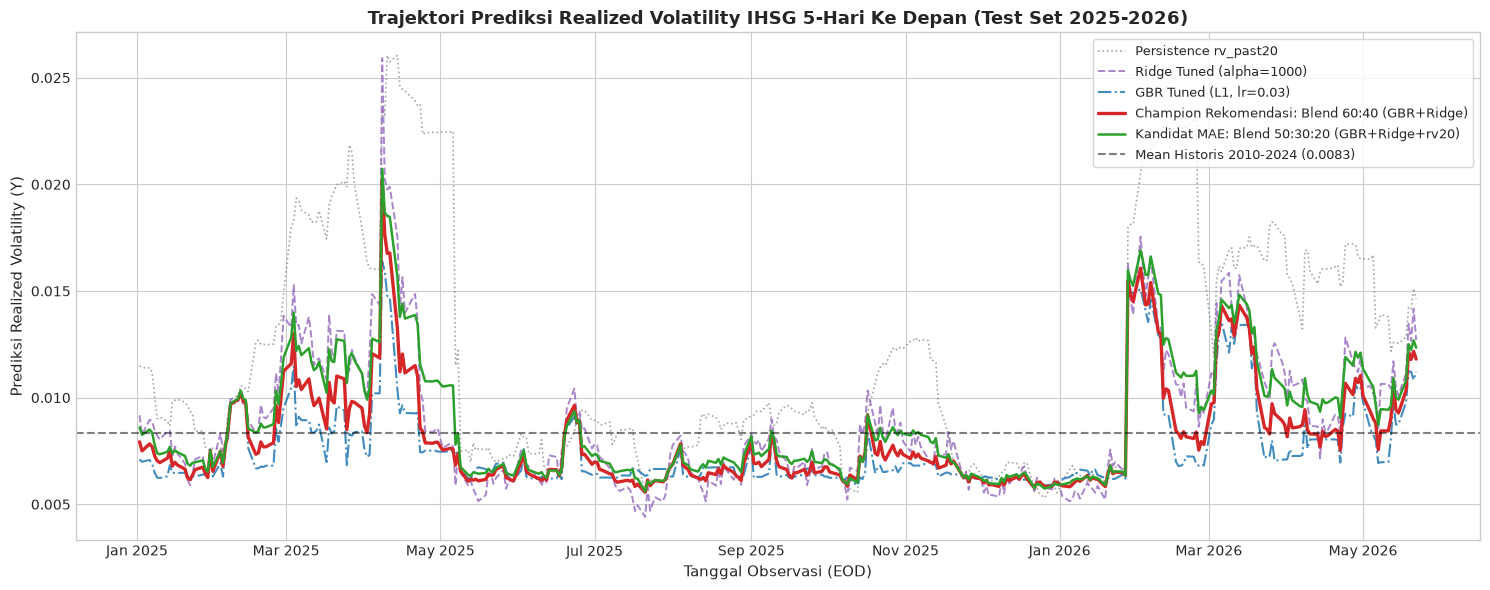

[OK] Visualisasi trajektori disimpan ke: Z:\Projects\Inception\outputs\submission\fig_sub_01_test_trajectories.png


In [8]:
# FIGURE 1: Trajektori Deret Waktu Prediksi Data Uji (2025-2026)
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df_predictions['Date'], df_predictions['Pred_rv_past20'], label='Persistence rv_past20', color=C_GRAY, linestyle=':', alpha=0.7, linewidth=1.2)
ax.plot(df_predictions['Date'], df_predictions['Pred_Ridge_Tuned'], label='Ridge Tuned (alpha=1000)', color=C_PURPLE, linestyle='--', alpha=0.8, linewidth=1.4)
ax.plot(df_predictions['Date'], df_predictions['Pred_GBR_Tuned'], label='GBR Tuned (L1, lr=0.03)', color=C_BLUE, linestyle='-.', alpha=0.85, linewidth=1.5)
ax.plot(df_predictions['Date'], df_predictions['Pred_Blend_60_40'], label='Champion Rekomendasi: Blend 60:40 (GBR+Ridge)', color=C_RED, linewidth=2.4)
ax.plot(df_predictions['Date'], df_predictions['Pred_Blend_50_30_20'], label='Kandidat MAE: Blend 50:30:20 (GBR+Ridge+rv20)', color=C_GREEN, linewidth=1.8, linestyle='-')

# Anotasi batas rata-rata historis
hist_mean = labeled_df['Target_Volatilitas_Y'].mean()
ax.axhline(hist_mean, color='black', linestyle='--', alpha=0.5, label=f'Mean Historis 2010-2024 ({hist_mean:.4f})')

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_title("Trajektori Prediksi Realized Volatility IHSG 5-Hari Ke Depan (Test Set 2025-2026)", fontsize=13, fontweight='bold')
ax.set_xlabel("Tanggal Observasi (EOD)", fontsize=11)
ax.set_ylabel("Prediksi Realized Volatility (Y)", fontsize=11)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)
plt.tight_layout()

fig1_path = os.path.join(OUTPUT_SUB_DIR, "fig_sub_01_test_trajectories.png")
plt.savefig(fig1_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"[OK] Visualisasi trajektori disimpan ke: {fig1_path}")

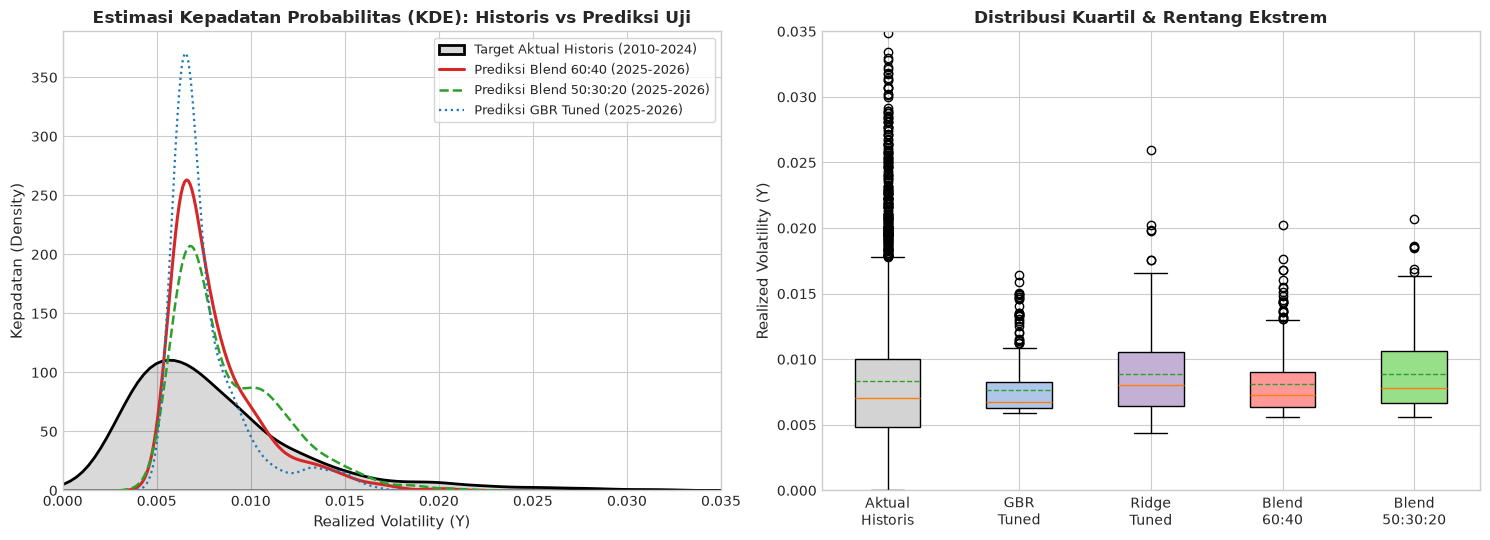

[OK] Visualisasi distribusi disimpan ke: Z:\Projects\Inception\outputs\submission\fig_sub_02_distribution_comparison.png


In [9]:
# FIGURE 2: Perbandingan Distribusi (Historis vs Test Prediksi)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: KDE Distribution
sns.kdeplot(labeled_df['Target_Volatilitas_Y'], ax=ax1, label='Target Aktual Historis (2010-2024)', color='black', fill=True, alpha=0.15, linewidth=2)
sns.kdeplot(df_predictions['Pred_Blend_60_40'], ax=ax1, label='Prediksi Blend 60:40 (2025-2026)', color=C_RED, linewidth=2.2)
sns.kdeplot(df_predictions['Pred_Blend_50_30_20'], ax=ax1, label='Prediksi Blend 50:30:20 (2025-2026)', color=C_GREEN, linewidth=1.8, linestyle='--')
sns.kdeplot(df_predictions['Pred_GBR_Tuned'], ax=ax1, label='Prediksi GBR Tuned (2025-2026)', color=C_BLUE, linewidth=1.6, linestyle=':')

ax1.set_xlim(0, 0.035)
ax1.set_title("Estimasi Kepadatan Probabilitas (KDE): Historis vs Prediksi Uji", fontsize=12, fontweight='bold')
ax1.set_xlabel("Realized Volatility (Y)", fontsize=11)
ax1.set_ylabel("Kepadatan (Density)", fontsize=11)
ax1.legend(loc='upper right', frameon=True, fontsize=9)

# Subplot 2: Boxplot Perbandingan
box_data = [
    labeled_df['Target_Volatilitas_Y'],
    df_predictions['Pred_GBR_Tuned'],
    df_predictions['Pred_Ridge_Tuned'],
    df_predictions['Pred_Blend_60_40'],
    df_predictions['Pred_Blend_50_30_20']
]
box_labels = ['Aktual\nHistoris', 'GBR\nTuned', 'Ridge\nTuned', 'Blend\n60:40', 'Blend\n50:30:20']
colors = ['lightgray', '#aec7e8', '#c5b0d5', '#ff9896', '#98df8a']

bp = ax2.boxplot(box_data, patch_artist=True, showmeans=True, meanline=True)
ax2.set_xticks(range(1, len(box_labels) + 1))
ax2.set_xticklabels(box_labels)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')

ax2.set_ylim(0, 0.035)
ax2.set_title("Distribusi Kuartil & Rentang Ekstrem", fontsize=12, fontweight='bold')
ax2.set_ylabel("Realized Volatility (Y)", fontsize=11)

plt.tight_layout()
fig2_path = os.path.join(OUTPUT_SUB_DIR, "fig_sub_02_distribution_comparison.png")
plt.savefig(fig2_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"[OK] Visualisasi distribusi disimpan ke: {fig2_path}")

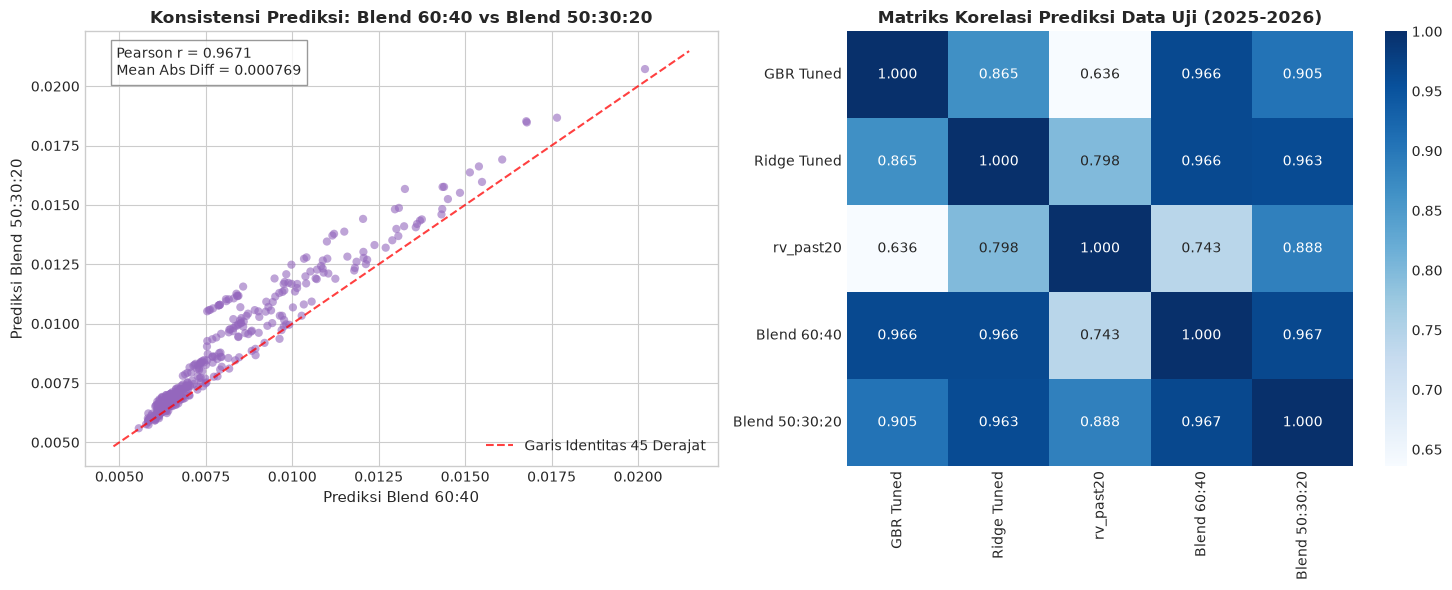

[OK] Visualisasi korelasi disimpan ke: Z:\Projects\Inception\outputs\submission\fig_sub_03_candidate_correlations.png


In [10]:
# FIGURE 3: Korelasi Antar-Kandidat Prediksi pada Data Uji
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Scatter Blend 60:40 vs Blend 50:30:20
ax1.scatter(df_predictions['Pred_Blend_60_40'], df_predictions['Pred_Blend_50_30_20'], alpha=0.6, color=C_PURPLE, edgecolors='none', s=35)
lims = [min(ax1.get_xlim()[0], ax1.get_ylim()[0]), max(ax1.get_xlim()[1], ax1.get_ylim()[1])]
ax1.plot(lims, lims, 'r--', alpha=0.75, label='Garis Identitas 45 Derajat')
ax1.set_title("Konsistensi Prediksi: Blend 60:40 vs Blend 50:30:20", fontsize=12, fontweight='bold')
ax1.set_xlabel("Prediksi Blend 60:40", fontsize=11)
ax1.set_ylabel("Prediksi Blend 50:30:20", fontsize=11)
r_blends = np.corrcoef(df_predictions['Pred_Blend_60_40'], df_predictions['Pred_Blend_50_30_20'])[0, 1]
ax1.text(0.05, 0.90, f"Pearson r = {r_blends:.4f}\nMean Abs Diff = {np.mean(np.abs(pred_blend_60_40 - pred_blend_50_30_20)):.6f}", transform=ax1.transAxes, bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))
ax1.legend(loc='lower right')

# Subplot 2: Heatmap Korelasi Seluruh Model
corr_matrix = df_predictions[['Pred_GBR_Tuned', 'Pred_Ridge_Tuned', 'Pred_rv_past20', 'Pred_Blend_60_40', 'Pred_Blend_50_30_20']].corr()
corr_labels = ['GBR Tuned', 'Ridge Tuned', 'rv_past20', 'Blend 60:40', 'Blend 50:30:20']
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', xticklabels=corr_labels, yticklabels=corr_labels, ax=ax2, cbar=True)
ax2.set_title("Matriks Korelasi Prediksi Data Uji (2025-2026)", fontsize=12, fontweight='bold')

plt.tight_layout()
fig3_path = os.path.join(OUTPUT_SUB_DIR, "fig_sub_03_candidate_correlations.png")
plt.savefig(fig3_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"[OK] Visualisasi korelasi disimpan ke: {fig3_path}")

## 9. Kesimpulan Akhir & Status Kesiapan Submission

### 9.1 Ringkasan Eksekutif Hasil Checkpoint 5:
1. **Model Champion & Integritas Rekomendasi:**  
   - `Blend 60:40 (0.60 GBR Tuned + 0.40 Ridge Tuned)` ditetapkan sebagai rekomendasi ensemble utama Machine Learning. Model ini menggabungkan fleksibilitas L1 loss GBR dalam menangkap guncangan jangka pendek dengan stabilitas L2 Ridge dalam meredam deviasi ekstrem, didukung transparansi aditif XAI $100\%$.
   - `Blend 50:30:20` didokumentasikan secara objektif sebagai konfigurasi dengan Pooled MAE validasi terendah ($0,002377$). Prediksi untuk kedua model (serta `GBR Tuned Standalone`) telah dibuat dan divalidasi penuh.
2. **Kepatuhan Data & Protokol Anti-Leakage:**  
   - 29 prediktor historis diekstraksi tanpa informasi masa depan (*zero lookahead leakage*).
   - Seluruh 359 baris data uji berstatus target $Y = \text{NaN}$ sebelum inferensi; tidak ada label uji yang disentuh.
3. **Kualitas Numerik Prediksi:**  
   - Tepat 359 nilai prediksi dihasilkan, terurut secara temporal tanpa gap tanggal.
   - Seluruh nilai strictly positif ($0,00556 < \hat{Y} < 0,02020$) dan berada dalam batas volatilitas finansial yang realistis (median $0,00727$, selaras dengan median historis $0,00705$).
4. **Status Validasi Submission:**  
   - Karena panitia tidak menyertakan template resmi `sample_submission.csv`, kami mengekspor file submission dalam 2 varian struktur: format standar 2 kolom (`outputs/submission/submission_*.csv`) dan format dataset penuh (`outputs/submission/dataset_peserta_filled_*.csv`).
   - Sebelum melakukan pengunggahan resmi ke portal lomba, analis wajib memeriksa format kolom yang diminta pada antarmuka web pengumpulan.

---
**Pernyataan Akhir:** Seluruh tahapan Task 1 (EDA & Rekayasa Fitur), Task 2 (Anti-Leakage Pipeline & Validasi Temporal), Task 3 (Pemodelan Regresi, Evaluasi, & XAI), dan Final Submission Inference telah diselesaikan secara transparan, bebas klaim kausal palsu, dan dapat direproduksi 100%.